# Step 2 · The objective and the cost filter

**Objective:** find recipes that **maximise cell count** (`y`) while **costing no more than the commercial baseline** (DMEM + 10 % FBS).

Two kinds of constraints define which recipes are allowed:
1. **Concentration limits:** each component between 0 and its maximum (already built into the 0-1 scale).
2. **Cost ceiling:** cost ≤ the baseline's cost, i.e. "more cells for no more money than today".

**Why this objective?**
- Cost is a known formula, so the constraint is a simple filter: no model needed.
- It is easy to explain to a business.
- The alternatives need extra choices: a weighted score of growth and cost needs arbitrary weights; a set of best trade-offs (Pareto front) needs multi-objective methods.

In [1]:
import matplotlib.pyplot as plt

from mediaopt.cost import BASELINE, COEF, baseline_cost, media_cost
from mediaopt.data import load_recipes

df = load_recipes()
df["cost"] = media_cost(df)
CEILING = baseline_cost()
print(f"cost ceiling (baseline DMEM + 10% FBS): {CEILING:.2f}")

cost ceiling (baseline DMEM + 10% FBS): 8.08


**Check:** the paper reports costs of 8.09 for the baseline and 8.22 for its optimal medium. Our formula should reproduce them.

In [2]:
best = df.loc[df.y.idxmax()]
print(f"baseline: {CEILING:.2f} (paper 8.09)   best recipe in data: {best.cost:.2f} (paper 8.22)")

baseline: 8.08 (paper 8.09)   best recipe in data: 8.21 (paper 8.22)


**What drives cost?** Each component's share of the total cost, averaged over the 25 recipes.

In [3]:
shares = (df[COEF.index] * COEF).div(df.cost, axis=0).mean().sort_values(ascending=False)
shares.head(4).round(3)

FBS      0.841
Glu      0.112
Albu     0.018
Gluta    0.012
dtype: float64

**Growth versus cost.** Recipes left of the line are within the ceiling.

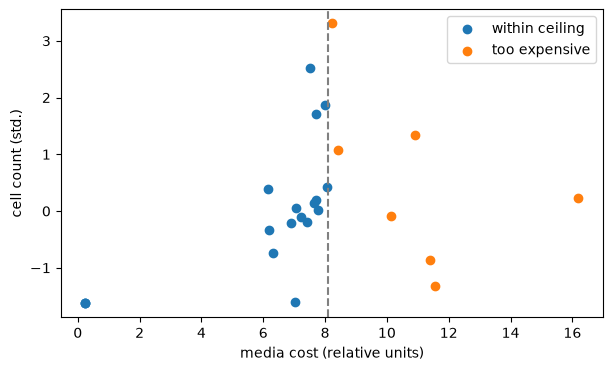

18 of 25 recipes are within the ceiling; best of them: y = 2.52


In [4]:
feasible = df.cost <= CEILING
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df.cost[feasible], df.y[feasible], label="within ceiling")
ax.scatter(df.cost[~feasible], df.y[~feasible], label="too expensive")
ax.axvline(CEILING, color="grey", linestyle="--")
ax.set_xlabel("media cost (relative units)")
ax.set_ylabel("cell count (std.)")
ax.legend()
plt.show()

best_feasible = df[feasible].y.max()
print(f"{feasible.sum()} of {len(df)} recipes are within the ceiling; best of them: y = {best_feasible:.2f}")

**Takeaways**
- **FBS is most of the cost** (≈ 84 % on average here). The cost ceiling is therefore close to a cap on serum: about 10 %.
- **The cost formula reproduces the paper's numbers**, so we can trust it to filter candidate recipes.
- **The bar to beat is y = 2.52:** the best recipe already measured within the ceiling.
- **The single best recipe (y = 3.31) costs 1.6 % *more* than the baseline**, so a strict ceiling excludes it. Where to put the ceiling is a business choice. We default to "no more than today" and test 0.75× and 1.25× later (step 6).
- Recipes far above the ceiling (lots of FBS or albumin) did *not* grow better: more expensive is not automatically better.